In [1]:
# Cell 1: Imports & Settings
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from typing import Tuple, Dict

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression, HuberRegressor, RANSACRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import joblib



In [2]:
# Plot settings
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
pd.set_option("display.precision", 3)


In [3]:
# Cell 2: Load Data
DATA_PATH = "/content/Home_Price_data_500.csv"  #

assert Path(DATA_PATH).exists(), f"File not found: {DATA_PATH}"
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
df.head()


Shape: (500, 4)


,Area,Bedrooms,Age,Price
0,2000,3.0,10,4000
1,2300,3.0,14,3800
2,2500,4.0,12,4000
3,2750,4.0,5,4200
4,2900,5.0,10,4200


In [4]:
#cell 3 – Quick Info, Types, Missing, Duplicates

# Cell 3: Structure & data quality
display(df.info())
display(df.describe())

# Missing values (%)
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)
print("\nMissing values (%):")
display(missing_pct.to_frame("missing_%"))

# Duplicates
dup_count = df.duplicated().sum()
print(f"\nDuplicate rows: {dup_count}")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Area      500 non-null    int64  
 1   Bedrooms  500 non-null    float64
 2   Age       500 non-null    int64  
 3   Price     500 non-null    int64  
dtypes: float64(1), int64(3)
memory usage: 15.8 KB


None

,Area,Bedrooms,Age,Price
count,500.000,500.000,500.000,500.000
mean,3034.422,6.451,11.876,5226.250
std,568.816,2.286,4.475,1015.996
min,2000.000,3.000,5.000,2933.000
25%,2560.500,4.000,8.000,4403.750
50%,3059.500,6.000,12.000,5210.000
75%,3509.250,8.000,16.000,6027.500
max,4000.000,10.000,20.000,7684.000



Missing values (%):


,missing_%
Area,0.0
Bedrooms,0.0
Age,0.0
Price,0.0



Duplicate rows: 0


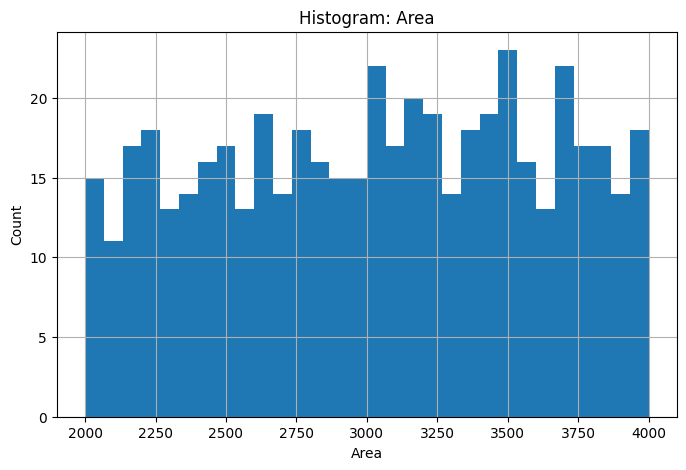

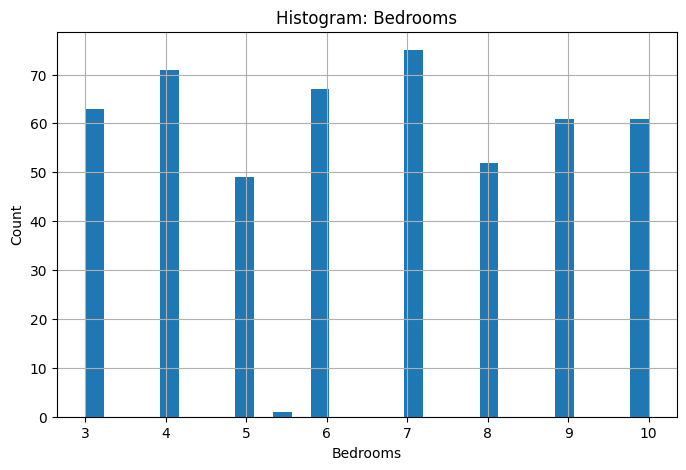

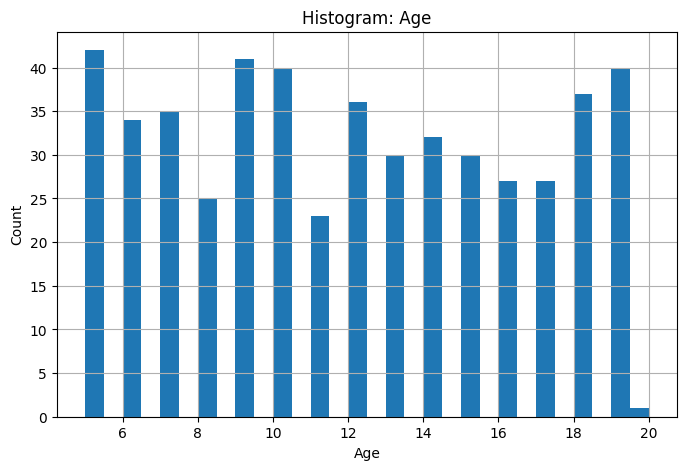

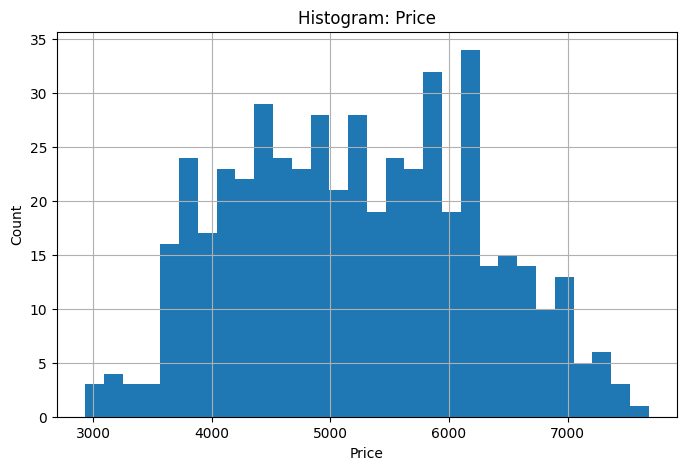

/tmp/ipython-input-3607141067.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(df[c].dropna(), vert=True, labels=[c])


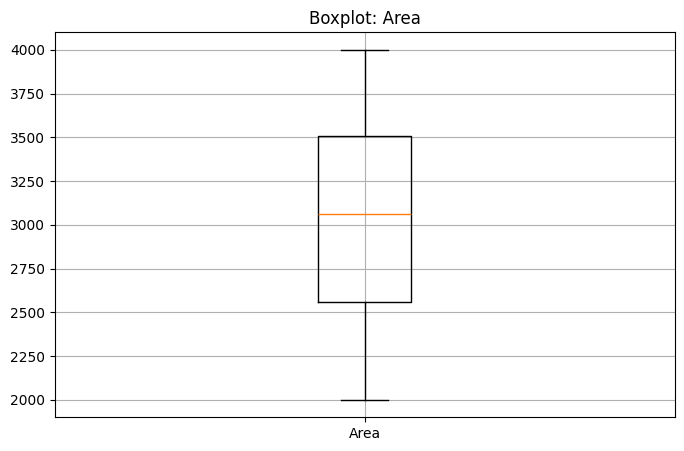

/tmp/ipython-input-3607141067.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(df[c].dropna(), vert=True, labels=[c])


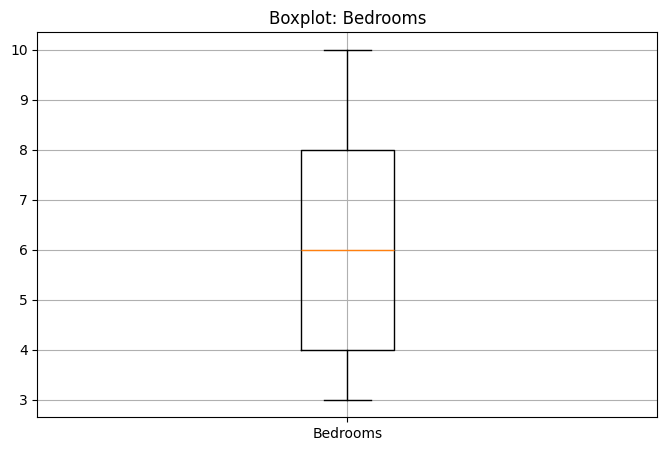

/tmp/ipython-input-3607141067.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(df[c].dropna(), vert=True, labels=[c])


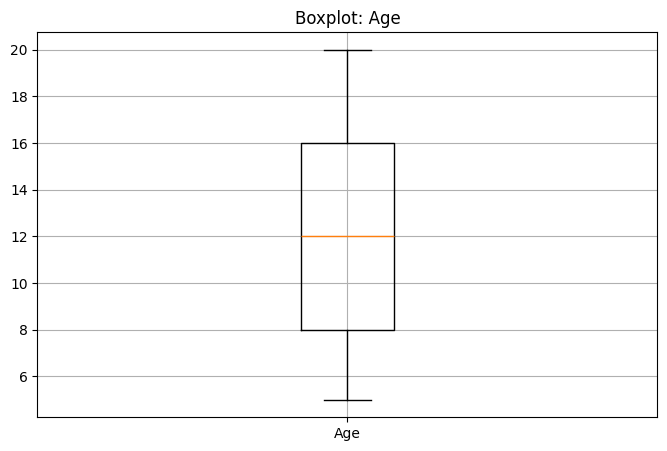

/tmp/ipython-input-3607141067.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(df[c].dropna(), vert=True, labels=[c])


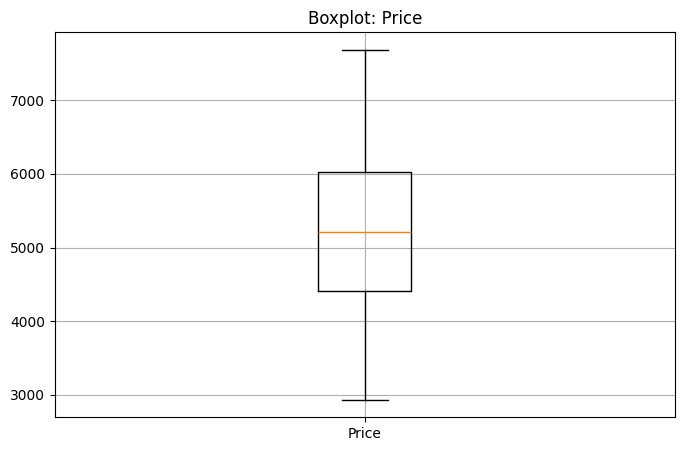

In [5]:
# Cell 4 – Distributions & Boxplots
# Cell 4: Distributions (hist) and boxplots
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# Histograms
for c in num_cols:
    plt.figure()
    plt.hist(df[c].dropna(), bins=30)
    plt.title(f"Histogram: {c}")
    plt.xlabel(c); plt.ylabel("Count")
    plt.show()

# Boxplots
for c in num_cols:
    plt.figure()
    plt.boxplot(df[c].dropna(), vert=True, labels=[c])
    plt.title(f"Boxplot: {c}")
    plt.show()


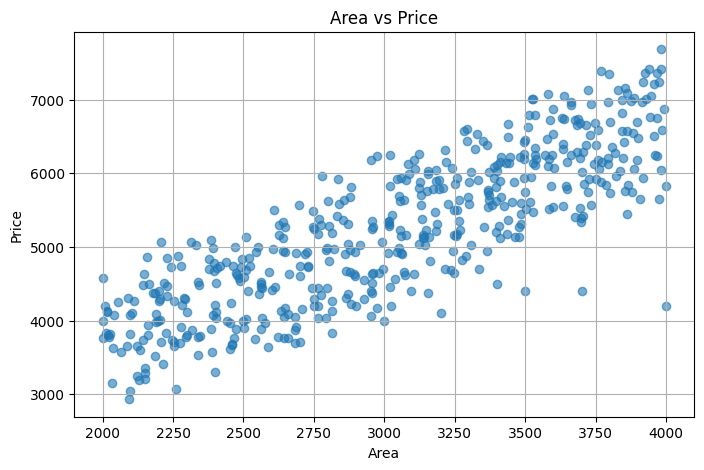

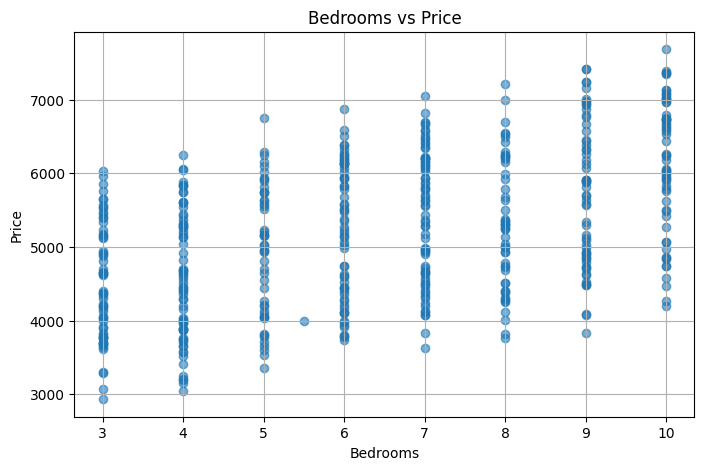

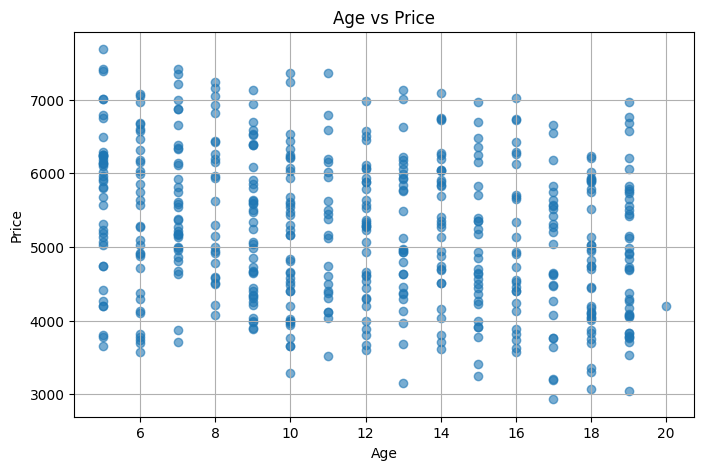

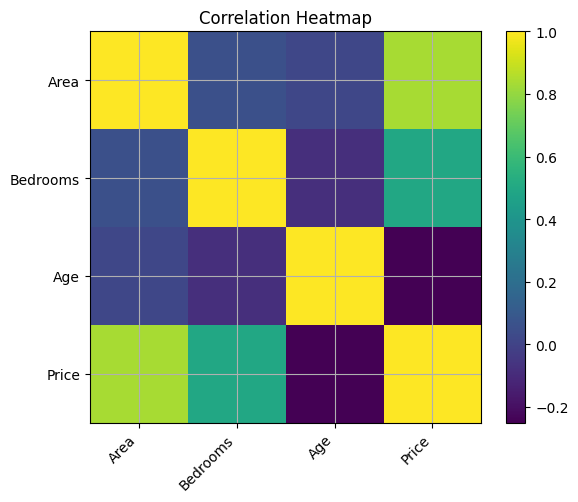

,Area,Bedrooms,Age,Price
Area,1.000,0.053,0.015,0.837
Bedrooms,0.053,1.000,-0.083,0.498
Age,0.015,-0.083,1.000,-0.251
Price,0.837,0.498,-0.251,1.000


In [6]:
# Cell 5 – Pairwise Scatter vs Target & Correlation Heatmap
# Cell 5: Scatter vs Price + Correlation heatmap
target = "Price"
features = [c for c in df.columns if c != target]

# Scatter plots vs target
for c in features:
    plt.figure()
    plt.scatter(df[c], df[target], alpha=0.6)
    plt.title(f"{c} vs {target}")
    plt.xlabel(c); plt.ylabel(target)
    plt.show()

# Correlation matrix (numerical only)
corr = df[num_cols].corr(numeric_only=True)

plt.figure(figsize=(6, 5))
plt.imshow(corr, interpolation='nearest')
plt.title("Correlation Heatmap")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha='right')
plt.yticks(range(len(corr.index)), corr.index)
plt.tight_layout()
plt.show()

corr


In [7]:
# Cell 6 – Targeted Cleaning (Missing/Types)

# Cell 6: Cleaning (minimal & targeted)

# Example: If Bedrooms had missing values, fill with median (column-only)
if df["Bedrooms"].isna().any():
    df["Bedrooms"].fillna(df["Bedrooms"].median(), inplace=True)

# Drop duplicates if any
if df.duplicated().sum() > 0:
    df = df.drop_duplicates().reset_index(drop=True)

# Ensure expected dtypes
expected = {"Area": "int64", "Bedrooms": "float64", "Age": "int64", "Price": "int64"}
for col, dt in expected.items():
    # Only cast if safe
    try:
        df[col] = df[col].astype(dt)
    except Exception as e:
        print(f"Skipping cast {col}->{dt}: {e}")

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Area      500 non-null    int64  
 1   Bedrooms  500 non-null    float64
 2   Age       500 non-null    int64  
 3   Price     500 non-null    int64  
dtypes: float64(1), int64(3)
memory usage: 15.8 KB


In [8]:
# Cell 7: Outliers via IQR, preview and optional winsorization

def iqr_bounds(series: pd.Series, k: float = 1.5) -> Tuple[float, float]:
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k*iqr, q3 + k*iqr

def count_outliers(series: pd.Series, k: float = 1.5) -> int:
    lb, ub = iqr_bounds(series, k)
    return int(((series < lb) | (series > ub)).sum())

print("Outlier counts (k=1.5):")
for c in num_cols:
    print(f"{c:>9}: {count_outliers(df[c], 1.5)}")

# OPTIONAL: mild winsorization on Price (1%/99%) to stabilize training if needed
winsorize = False  # set True to apply
if winsorize:
    low, high = df["Price"].quantile([0.01, 0.99])
    df["Price"] = df["Price"].clip(lower=low, upper=high)
    print(f"\nApplied winsorization to Price: [{low:.2f}, {high:.2f}]")


Outlier counts (k=1.5):
     Area: 0
 Bedrooms: 0
      Age: 0
    Price: 0


In [9]:
# Cell 8: Train-test split
target = "Price"
X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
X_train.shape, X_test.shape


((400, 3), (100, 3))

In [12]:
# Cell 9: Train baseline Linear Regression (version-agnostic RMSE)
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

lin = LinearRegression()
lin.fit(X_train, y_train)

y_pred = lin.predict(X_test)

R2  = r2_score(y_test, y_pred)
MAE = mean_absolute_error(y_test, y_pred)

# Version-agnostic RMSE (works even if 'squared' kwarg is unsupported)
try:
    RMSE = mean_squared_error(y_test, y_pred, squared=False)
except TypeError:
    RMSE = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Linear Regression -> R²={R2:.4f} | MAE={MAE:.2f} | RMSE={RMSE:.2f}")

coef_table = pd.DataFrame({
    "feature": X.columns,
    "coefficient": lin.coef_
}).sort_values("coefficient", ascending=False).reset_index(drop=True)

print("\nIntercept:", round(lin.intercept_, 3))
display(coef_table)

preview = pd.DataFrame({
    "Actual": y_test.reset_index(drop=True),
    "Predicted": pd.Series(y_pred).round(2)
})
preview.head(10)


Linear Regression -> R²=0.9324 | MAE=61.01 | RMSE=244.56

Intercept: 124.793


,feature,coefficient
0,Bedrooms,195.105
1,Area,1.471
2,Age,-52.264


,Actual,Predicted
0,4523,4481.94
1,5582,5587.64
2,3736,3743.71
3,7008,6994.94
4,4442,4441.04
5,5068,5060.74
6,5290,5299.51
7,4818,4781.57
8,5991,6011.19
9,4289,4321.47


In [13]:
# Cell 10: Cross-validation (R²)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(LinearRegression(), X, y, cv=kf, scoring='r2')
print("CV R² scores:", np.round(cv_scores, 4))
print("CV R² mean  :", cv_scores.mean().round(4), "±", cv_scores.std().round(4))


CV R² scores: [0.9324 0.9669 0.8995 0.9682 0.9962]
CV R² mean  : 0.9527 ± 0.0334


In [19]:
# Cell 15: What-if grid (Area varies; Bedrooms/Age fixed)
base_bed = 4.0
base_age = 10

grid = pd.DataFrame({
    "Area": np.arange(1500, 3501, 250),
    "Bedrooms": base_bed,
    "Age": base_age
})
grid["PredictedPrice"] = MODEL.predict(grid)

grid


,Area,Bedrooms,Age,PredictedPrice
0,1500,4.0,10,2588.881
1,1750,4.0,10,2956.600
2,2000,4.0,10,3324.318
3,2250,4.0,10,3692.037
4,2500,4.0,10,4059.756
5,2750,4.0,10,4427.475
6,3000,4.0,10,4795.194
7,3250,4.0,10,5162.913
8,3500,4.0,10,5530.631


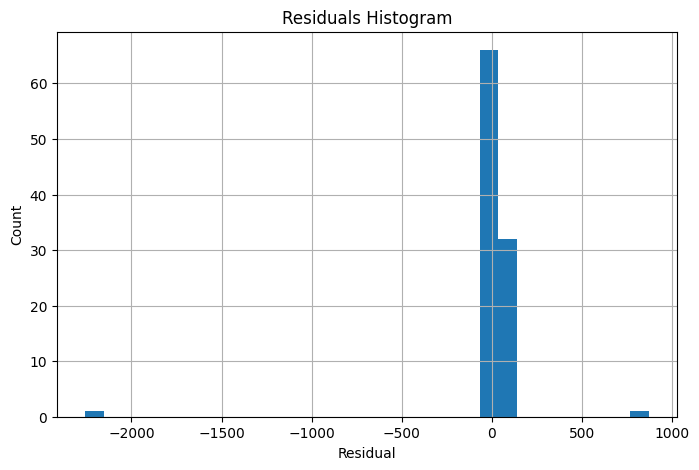

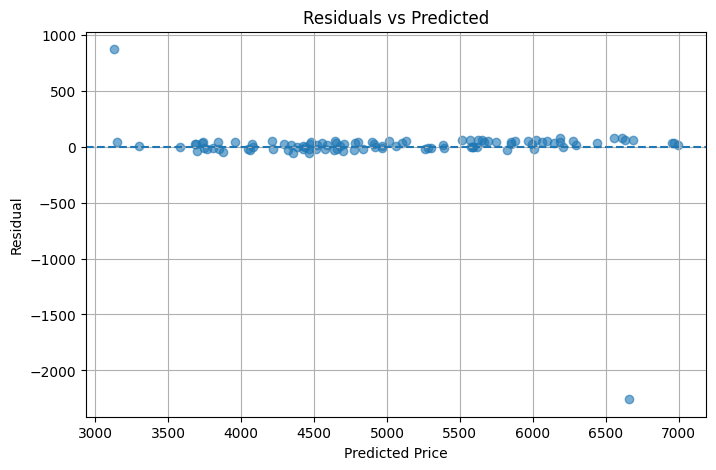

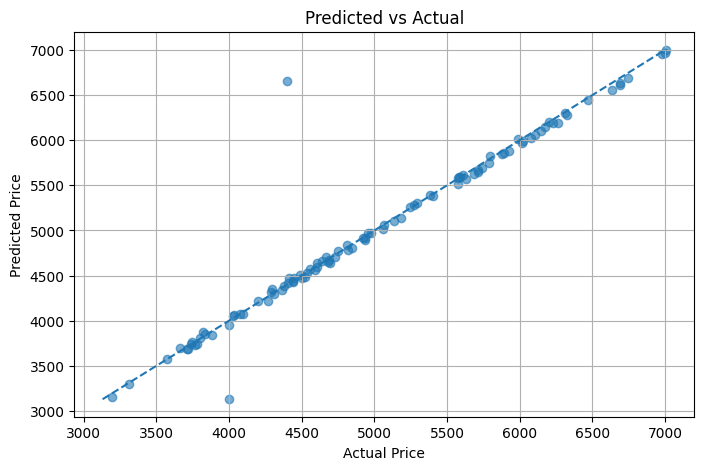

In [14]:
# Cell 11: Residual diagnostics
residuals = y_test.to_numpy() - y_pred

# Residual histogram
plt.figure()
plt.hist(residuals, bins=30)
plt.title("Residuals Histogram")
plt.xlabel("Residual"); plt.ylabel("Count")
plt.show()

# Residuals vs Predicted
plt.figure()
plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(0, linestyle="--")
plt.title("Residuals vs Predicted")
plt.xlabel("Predicted Price"); plt.ylabel("Residual")
plt.show()

# Predicted vs Actual
plt.figure()
plt.scatter(y_test, y_pred, alpha=0.6)
minv, maxv = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())
plt.plot([minv, maxv], [minv, maxv], linestyle="--")
plt.title("Predicted vs Actual")
plt.xlabel("Actual Price"); plt.ylabel("Predicted Price")
plt.show()


In [15]:
# Cell 13: Persist model & metadata
ARTIFACT_DIR = Path("./artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)

model_path = ARTIFACT_DIR / "linear_home_price_model.joblib"
meta_path  = ARTIFACT_DIR / "model_metadata.json"

joblib.dump(lin, model_path)

meta = {
    "features": X.columns.tolist(),
    "target": target,
    "metrics": {"R2": float(R2), "MAE": float(MAE), "RMSE": float(RMSE)},
    "intercept": float(lin.intercept_),
    "coefficients": {f: float(c) for f, c in zip(X.columns, lin.coef_)},
}
pd.Series(meta, dtype="object").to_json(meta_path, indent=2)

print("Saved:", model_path)
print("Saved:", meta_path)


Saved: artifacts/linear_home_price_model.joblib
Saved: artifacts/model_metadata.json


In [18]:
import json
import joblib
import pandas as pd

# Load artifacts
with open("/content/artifacts/model_metadata.json", "r") as f:
    meta = json.load(f)

MODEL = joblib.load("/content/artifacts/linear_home_price_model.joblib")
FEATURES = meta["features"]   # now a plain Python list

def predict_price(area: float, bedrooms: float, age: float) -> float:
    """ Predict home price given area, bedrooms, age. """
    row = pd.DataFrame([[area, bedrooms, age]], columns=FEATURES)
    return float(MODEL.predict(row)[0])

# Example usage
print("Example prediction:", round(predict_price(2500, 4, 10), 2))


Example prediction: 4059.76


In [21]:
# Cell 16: Simple CLI prompt (optional)

A = float(input("Enter Area (sqft): "))
B = float(input("Enter Bedrooms: "))
G = float(input("Enter Age (years): "))
print("Predicted Price:", round(predict_price(A, B, G), 2))


Enter Area (sqft): 4000
Enter Bedrooms: 6
Enter Age (years): 20
Predicted Price: 6133.63
